# zf1 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830, SR860
from qcodes.instrument_drivers.Keithley import Keithley2400
from qcodes.instrument_drivers.american_magnetics import AMIModel430

import sweep

from hera.analysis import GateCalibration

from sharpelab_nb.constants import TOPLOADER
from sharpelab_nb.thermometry import temperature_from_logfile
from sharpelab_nb.drivers import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\toploader\\measurements\\aaron\\zf1_toploader'

# Connect Instruments

## Magnet

In [3]:
MAGNET_ADDR = "TCPIP0::192.168.0.101::7180::SOCKET"  # <-- verify address
magnet = AMIModel430("magnet", address=MAGNET_ADDR)
# Field in Tesla; magnet.field() is the MEASURED readback (coil constant
# 0.116783 T/A is configured on the unit). magnet.field(target) BLOCKS until
# the supply reports holding; a kernel interrupt does NOT stop the ramp.
magnet.field()

Connected to: AMERICAN MAGNETICS INC. 430 (serial:430-11-044, firmware:2.65) in 1.04s


2.0312e-05

## Thermometry (file-based) + sample heater

Kernel temperature reads are **file-based**, not GPIB — the AVS bridge workers
own the bridges and write the logfiles. `temperature` is the loaded probe's
mixing chamber; the logfile path is **probe-dependent** (Probe1 = straight,
Probe2 = rotator). The sample heater is an **open-loop** Keithley voltage
source — set `heater.volt`, settle, then read T back from `temperature()`.

In [4]:
# Probe MC (sample T) — point at the LOADED probe (Probe1 straight / Probe2 rotator)
temperature = temperature_from_logfile(
    "T", r"C:\Users\toploader\temperature_logs\Probe2_MixingCh_low.txt")  # <-- verify probe
fridge_temperature = temperature_from_logfile("T_fridge", TOPLOADER.temp_logfiles["T_fridge"])
mag_temperature = temperature_from_logfile("T_magnet", TOPLOADER.temp_logfiles["T_magnet"])
print("probe MC:", temperature(), "K")

# Sample-stage heater — open-loop voltage drive (V->T is per-cooldown; device card)
heater = Keithley2400("heater", "GPIB4::12::INSTR")  # <-- verify address
heater.mode.set("VOLT")
heater.volt.step = 0.005

probe MC: 0.0337 K
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1299232, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.11s


## Lock-ins

In [5]:
sr830_1 = SR830("sr830_1", "GPIB0::8::INSTR")  # <-- verify — current channel (Ithaco 1211 preamp output)
sr830_2 = SR830("sr830_2", "GPIB0::9::INSTR")  # <-- verify
sr830_3 = SR830("sr830_3", "GPIB0::4::INSTR")  # <-- verify
sr830_4 = SR830("sr830_4", "GPIB0::1::INSTR")  # <-- verify
sr830_5 = SR830("sr830_5", "GPIB0::5::INSTR")  # <-- verify
sr830_6 = SR830("sr830_6", "GPIB0::6::INSTR")  # <-- verify
sr830_7 = SR830("sr830_7", "GPIB0::7::INSTR")  # <-- verify
# sr830_8 = SR860("sr830_8", "TCPIP::192.168.0.107::inst0::INSTR")  # <-- verify — SR860; enable if used

C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_2 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

Connected to: Stanford_Research_Systems SR830 (serial:s/n45469, firmware:ver1.07) in 0.15s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45595, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45471, firmware:ver1.07) in 0.11s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_4 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_4 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

Connected to: Stanford_Research_Systems SR830 (serial:s/n43722, firmware:ver1.07) in 0.10s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45470, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n43721, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41621, firmware:ver1.07) in 0.09s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_6 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_6 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_7 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

## Keithleys (gates)

In [10]:
# Gate Keithleys are role-named on this rig (k_tg/k_bg drive top/back gates),
# so recipes' k_tg / k_bg resolve directly. The third Keithley's role is
# per-insert (Si gate, or a probe-specific winding). Defaults: rangev 21,
# rangei 1uA, compliance 10 nA / 20 V, step 5 mV.
def _setup_k2400(k):
    k.mode.set("VOLT")
    k.rangev.set(21)
    k.rangei.set(1e-6)
    k.compliancev.set(20)
    k.compliancei.set(1e-6)
    k.volt.step = 0.005
    return k

k_tg  = _setup_k2400(Keithley2400("k_tg",  "GPIB4::9::INSTR"))   # <-- verify — top gate
k_bg  = _setup_k2400(Keithley2400("k_bg",  "GPIB4::10::INSTR"))  # <-- verify — back gate
k_tg2 = _setup_k2400(Keithley2400("k_tg2", "GPIB4::11::INSTR"))  # <-- verify — third Keithley (per-insert role)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028439, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028442, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028489, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s


## DC205 (DC current bias)

On the toploader, gates are Keithleys; the DC205s are **DC current-bias**
sources (through a 100 MΩ series resistor — see the device card). Set
`volt -> 0` before reconfiguring or ending a measurement.

In [11]:
dc205_1 = SRS_DC205("dc205_1", "ASRL6::INSTR")  # <-- verify address — DC current bias
dc205_1.volt = dc205_1.voltage
dc205_1.volt.step = 0.005

dc205_3 = SRS_DC205("dc205_3", "ASRL7::INSTR")  # <-- verify address — second DC205
dc205_3.volt = dc205_3.voltage
dc205_3.volt.step = 0.005

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500516, firmware:ver1.80) in 0.04s
Connected to: Stanford_Research_Systems DC205 (serial:s/n20500513, firmware:ver1.80) in 0.04s


# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [14]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`.
TG_MIN, TG_MAX = -7.0, +6.0   # top gate (k_tg), V    # <-- validate
BG_MIN, BG_MAX = -4.0, +4.2   # back gate (k_bg), V    # <-- validate
k_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter, so
# this validator rejects magnet.field(target) with |B| > cap before any
# hardware traffic. Driver backstop: |B| <= COIL? x current_limit (~9 T) on the
# AMI430 unit.
B_SESSION_CAP = 0.1  # Tesla (100 mT, brief)    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Sample-heater ceiling for sustained runs (V, not T — open-loop drive).
HEATER_V_MAX = 6.5  # V    # <-- validate
heater.volt.vals = validators.Numbers(0, HEATER_V_MAX)

# DC current-bias range (SRS DC205 hardware: +/-15 V -> +/-150 nA at 100 MOhm).
dc205_1.volt.vals = validators.Numbers(-15, 15)

# Helpers

In [15]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [16]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 23.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 20e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [17]:
# slot: meas-config — channel/contact assignments + gains from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Toploader contacts are wired
# DIRECT (no QSwitch) — name the contact pair per channel. Always set 'comment'
# per run — structured, current, no inherited text.
meas_config = {
    "sr1": "5-4",   "sr1_gain": -1e6,   # current channel (Ithaco 1211)    # <-- validate
    "sr2": "5-4",   "sr2_gain": 1e2,    # <-- validate
    "sr3": "30-31", "sr3_gain": 1e2,    # <-- validate
    "sr4": "5-30",  "sr4_gain": 1e2,    # 4th ch from card provided config    # <-- validate
    "bias_resistor": 1e8,
    "bias_voltage_1": sr830_1.amplitude(),
    "lockin_freq_1": sr830_1.frequency(),
    "comment": "<SET PER RUN>",
}

# HERA — session start (2026-06-20) — zf1

## HERA — Gate C: liveness / wiring sanity (first-session, no references)

Bring-up is green (instruments connected & reading; SAFETIES exec [14] matches the device card; magnet 0.02 mT, probe MC 33.7 mK). Last open [VERIFY]: confirm the provided contact wiring reads cleanly and a four-terminal Rxx channel is live — **before** committing hours to the Step-1 gate map.

**Wiring under test** (provided config, no mux): `sr1=5-4` current drive · `sr2=5-4` 2-terminal · **`sr3=30-31` the genuine 4-terminal Rxx** (off both current contacts) · `sr4=5-30` (shares drive contact 5). `sr3` and `sr4` both touch contact **30** — the b1c2 precedent on this rig hit a grounded-short on a shared contact 30 (all voltage channels locked to ground, a flat-nonzero *false* signal). A static read can't see that; a sweep can.

**This cell** (slug `gate-current-sanity-check`): one cheap leg — `k_bg` swept across its full committed validator (−4 → +4.2 V) at `k_tg = 0`, all gates parked, `nplci=10` on the gate-current channels for pA-floor leakage readback (reset to 1 in `finally`). Confirms in one shot: (i) current channel ~1 nA → device passes current; (ii) `sr3` X varies smoothly with gate → 4T channel alive, not flat / grounded-short; (iii) gate currents stay in pA across the leg → no leakage inside the validators; (iv) first hint of where the CNP line crosses TG=0, to size the Step-1 gatemap box. **Pristine field preserved** — does not touch the magnet controller (Step-1 map-before-energise discipline intact).

**Preconditions** (asserted in-cell): T at base (<100 mK), |B|<5 mT, gate setpoints printed. **Watch the live plot:** any voltage channel flat, or all channels pinned to one value → grounded-short, stop. Gate current rolling into nA → leakage, interrupt. **~3 min** (ramp to −4 V start + 83 pts × ~1.5 s with nplci=10).


precond: probe MC T = 33.7 mK (expect base, <100 mK)
precond: magnet field = -0.0029 mT (expect ~0; magnet untouched this session)
precond: gate setpoints  k_tg=+0.000 V  k_bg=+0.000 V
2026-06-20 14:01:37,459 [INFO] Ramping k_tg_volt: 0.0 -> 0
2026-06-20 14:01:37,978 [INFO] Ramping k_bg_volt: 0.0 -> -4.0
2026-06-20 14:01:43,168 [INFO] Starting sweep with ID 0
2026-06-20 14:01:43,169 [INFO] Minimum duration 0h 1m 23s


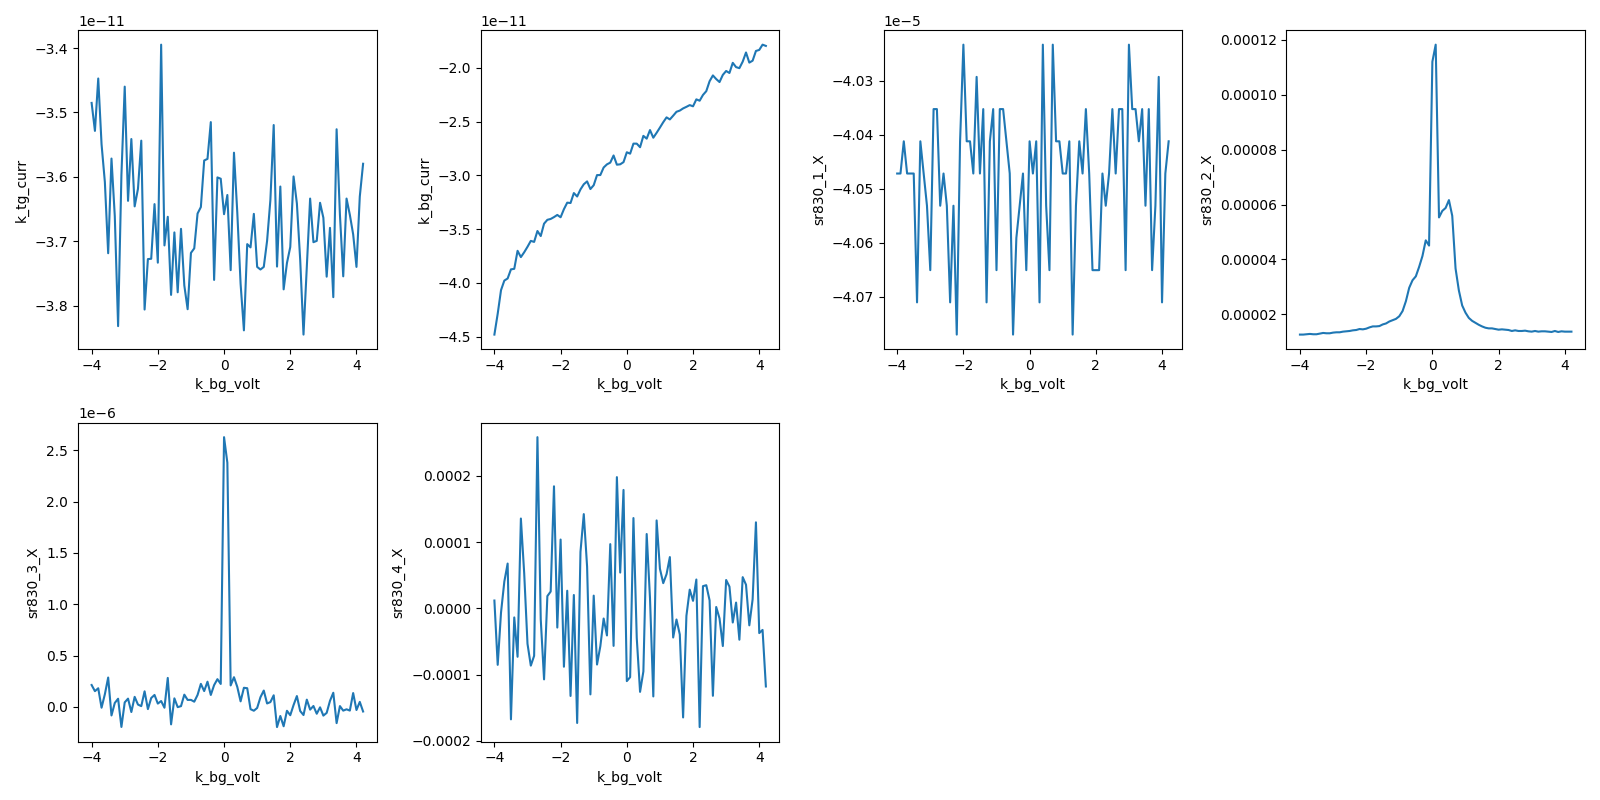

2026-06-20 14:04:43,578 [INFO] Completed in 0h 2m 59s
2026-06-20 14:04:43,579 [INFO] Data saved in C:\Users\toploader\measurements\aaron\zf1_toploader\data\0\data.tsv.gz
2026-06-20 14:04:44,090 [INFO] Ramping k_bg_volt: 4.2 -> 0


In [18]:
import numpy as np

# --- preconditions: state this cell assumes but does not set ---
T = temperature()
B = magnet.field()
print(f"precond: probe MC T = {T*1e3:.1f} mK (expect base, <100 mK)")
print(f"precond: magnet field = {B*1e3:.4f} mT (expect ~0; magnet untouched this session)")
print(f"precond: gate setpoints  k_tg={k_tg.volt():+.3f} V  k_bg={k_bg.volt():+.3f} V")
assert T < 0.1, f"T not at base: {T} K"
assert abs(B) < 0.005, f"field unexpectedly finite: {B} T"

# pA-floor leakage readback for the gate-current channels (reset to 1 below)
k_tg.nplci(10)
k_bg.nplci(10)

meas_config["comment"] = (
    "Gate C liveness: k_bg -4 -> +4.2 V leg at k_tg=0, B~0; "
    "confirm 4T Rxx (sr3 30-31) live, current channel passes ~1 nA, "
    "no gate leakage, not a grounded-short"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('gate-current-sanity-check')
s.add_comment('liveness leg: k_bg -4.0 -> +4.2 V, k_tg=0, B~0')

s.ramp(k_tg.volt, 0)
s.ramp(k_bg.volt, -4.0)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3, sr830_4):
    s.fp(lia.X).fp(lia.P)

xp = k_bg.volt
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3, sr830_4):
    s.plot(xp, lia.X)

try:
    s.sweep(k_bg.volt, np.linspace(-4.0, 4.2, 83), delay=1)
finally:
    s.ramp(k_bg.volt, 0)
    k_tg.nplci(1)
    k_bg.nplci(1)


## HERA — TG leakage/SNR leg @ 0.5 nA, before the candidate map

Gate C (run 0) passed: device alive, 4T Rxx (sr3, 30-31) live, no leakage on BG, CNP at k_bg≈0. Two gaps to close cheaply before committing to the ~hours Step-1 gate map:

1. **TG extremes untested this session** — run 0 only swept BG at k_tg=0. The map's slow axis will drive TG to −7 / +6 for the first time. The **negative** side is the riskier one (device card: hBN leakage onset is *higher* on +V, so −7 V sits nearer onset). Walk TG **0 → −7 V** from zero with gate leakage live-plotted at pA resolution (nplci=10) — confirm the committed −7 V validator is still safe this cooldown *before* the map drives it 80× over. (The +6 V side — the safer polarity — is validator-trusted and will be confirmed live in the map's first rows + checkpoint.)
2. **Validate the 0.5 nA drive** — bump `sr830_1.amplitude` 0.004 → **0.05 V** (40 pA → 0.5 nA; the card's nominal is 1 nA, 0.5 nA is the SC-friendly value from `sc-characterization` Step 2). This leg runs away from the CNP into the metallic **low-Rxx band** — exactly where run 0's 40 pA noise floor (~26–68 Ω) buried the signal. Expect the 4T noise floor to drop to ~5 Ω, confirming candidate-low-Rxx will be resolvable on the map.

**Preconditions** (asserted): T base (<100 mK), |B|<5 mT, gates printed. **Watch the live gate-current plot** — if |I_tg| climbs toward the 100 pA line / rolls into nA, interrupt (`nb-collab interrupt`); that's leakage onset and we back off the TG validator. `try/finally` parks TG→0 and resets nplci→1. **~3 min** (71 pts × ~1.7 s + park-back ramp).


precond: probe MC T = 33.7 mK (expect base, <100 mK)
precond: magnet field = 0.0192 mT (expect ~0; magnet untouched)
precond: gate setpoints  k_tg=+0.000 V  k_bg=+0.000 V
AC drive: sr830_1.amplitude = 50 mV -> I_bias = 0.500 nA
2026-06-20 14:16:11,607 [INFO] Ramping k_bg_volt: 0.0 -> 0
2026-06-20 14:16:12,119 [INFO] Ramping k_tg_volt: 0.0 -> 0
2026-06-20 14:16:12,127 [INFO] Starting sweep with ID 1
2026-06-20 14:16:12,128 [INFO] Minimum duration 0h 1m 11s


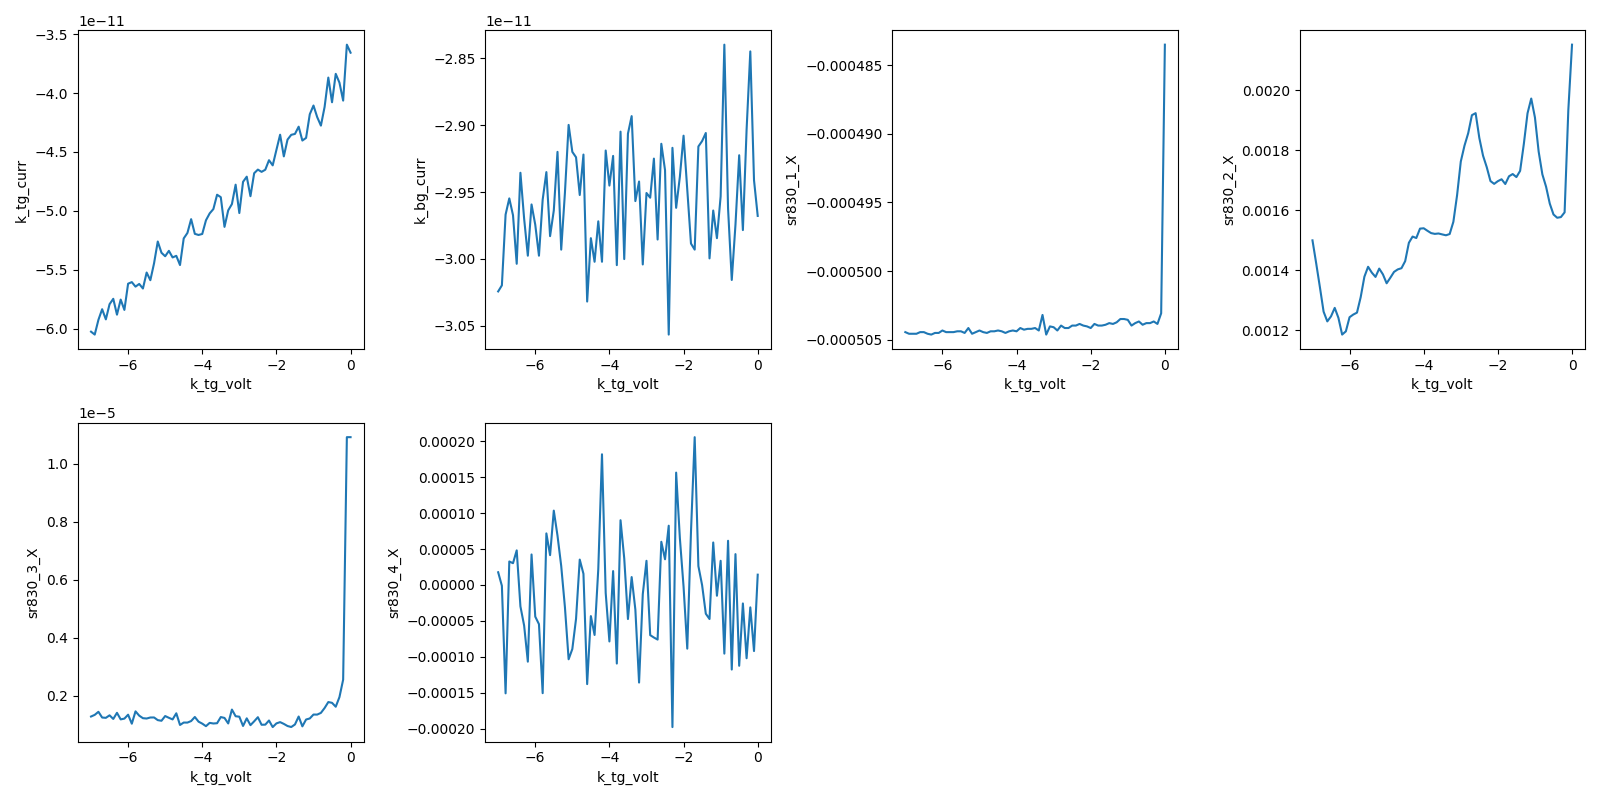

2026-06-20 14:18:45,904 [INFO] Completed in 0h 2m 33s
2026-06-20 14:18:45,905 [INFO] Data saved in C:\Users\toploader\measurements\aaron\zf1_toploader\data\1\data.tsv.gz
2026-06-20 14:18:46,417 [INFO] Ramping k_tg_volt: -7.0 -> 0


In [19]:
import numpy as np

# --- preconditions: state this cell assumes but does not set ---
T = temperature()
B = magnet.field()
print(f"precond: probe MC T = {T*1e3:.1f} mK (expect base, <100 mK)")
print(f"precond: magnet field = {B*1e3:.4f} mT (expect ~0; magnet untouched)")
print(f"precond: gate setpoints  k_tg={k_tg.volt():+.3f} V  k_bg={k_bg.volt():+.3f} V")
assert T < 0.1, f"T not at base: {T} K"
assert abs(B) < 0.005, f"field unexpectedly finite: {B} T"

# --- drive bump: 40 pA -> 0.5 nA for low-Rxx SNR (card nominal 1 nA; 0.5 nA = SC-friendly) ---
sr830_1.amplitude(0.05)
meas_config["bias_voltage_1"] = sr830_1.amplitude()
print(f"AC drive: sr830_1.amplitude = {sr830_1.amplitude()*1e3:.0f} mV -> "
      f"I_bias = {meas_config['bias_voltage_1']/meas_config['bias_resistor']*1e9:.3f} nA")

# pA-floor leakage readback on gate-current channels (reset to 1 below)
k_tg.nplci(10)
k_bg.nplci(10)

meas_config["comment"] = (
    "TG leakage/SNR leg: k_tg 0 -> -7 V at k_bg=0, B~0, drive 0.5 nA; "
    "confirm -7 V TG validator safe this cooldown + validate low-Rxx SNR floor"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('gate-current-sanity-check')
s.add_comment('TG leg: k_tg 0 -> -7.0 V, k_bg=0, B~0, drive 0.5 nA')

s.ramp(k_bg.volt, 0)
s.ramp(k_tg.volt, 0)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3, sr830_4):
    s.fp(lia.X).fp(lia.P)

xp = k_tg.volt
s.plot(xp, k_tg.curr)
s.plot(xp, k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3, sr830_4):
    s.plot(xp, lia.X)

try:
    s.sweep(k_tg.volt, np.linspace(0, -7.0, 71), delay=1)
finally:
    s.ramp(k_tg.volt, 0)
    k_tg.nplci(1)
    k_bg.nplci(1)


## HERA — Step 1: pristine-field gate map (candidate ID)

Bring-up complete (runs 0–1): device alive, 4T Rxx (sr3, 30-31) live at ~2.6 Ω noise floor @ 0.5 nA, both gate validators exercised clean (BG ±4: ≤45 pA; TG 0→−7: ≤61 pA), CNP at ≈(k_tg 0, k_bg 0). This is the **investigation Step 1** map — `gatemap` (axis-aligned in raw V_tg/V_bg, since the cap-ratio/geometry prior is unconfirmed; this map is the substrate for `cnp-and-dline-calibration`). **Taken before the magnet is ever energised** — the field-history protocol's map-before-energise step (asserted |B|<5 mT in-cell).

**What:** 2D megasweep over the full validator box. **BG slow** −4→+4.2 V (61 pts, 0.137 V) × **TG fast** −7→+6 V (101 pts, 0.13 V), `slow_delay=3, fast_delay=1`, drive 0.5 nA, B≈0. All lock-ins + both gate currents read at every point. Grid ~0.13 V resolves SC domes ≳0.25 V wide; coarse-first reconnaissance per the investigation (zoom into candidates after).

**Why TG fast:** the +6 V TG corner is the one extreme not yet exercised this session (safer polarity, validator-trusted). As the fast axis, TG sweeps to +6 at the end of **row 1** (~3 min) and every row after, keeping the worst leakage corner under the live `k_tg.curr` plot throughout.

**Price:** ~6161 pts. From run 1's measured 2.18 s/pt (nplci=10); map runs nplci=1 → ~1.9 s/pt → **~3.5 hr** (3–4 hr realistic, incl. fast-axis retrace + 61 slow settles). Quoted as the realistic case, not the floor.

**Checkpoint @ ~12 BG rows (~40 min):** I'll read the partial run from disk — (i) leakage stayed <100 pA across the +6/−7 corners; (ii) no channel flat/saturated; (iii) the CNP ridge is forming where expected; (iv) any low-Rxx candidate regions. Fork: continue / re-scope the box / abandon. `hera-watch` armed to digest the rows live.

**Preconditions** (asserted in-cell): T base (<100 mK); **|B|<5 mT (pristine field — magnet untouched)**; drive = 0.5 nA (sr830_1.amplitude=0.05); gate setpoints printed. **Watch the live `k_tg.curr` / `k_bg.curr` plots** — if either climbs toward 100 pA / rolls into nA at any corner, interrupt (`nb-collab interrupt`); that's leakage onset, we re-scope the box. Gates park to 0 at the end.


In [20]:
import numpy as np
import time

# --- preconditions: state this cell assumes but does not set ---
T = temperature()
B = magnet.field()
print(f"precond: probe MC T = {T*1e3:.1f} mK (expect base, <100 mK)")
print(f"precond: magnet field = {B*1e3:.4f} mT (PRISTINE — magnet must be untouched, |B|<5 mT)")
print(f"precond: gate setpoints  k_tg={k_tg.volt():+.3f} V  k_bg={k_bg.volt():+.3f} V")
assert T < 0.1, f"T not at base: {T} K"
assert abs(B) < 0.005, f"field not pristine: {B} T — Step-1 map must precede energising the magnet"

# --- drive at the validated 0.5 nA (idempotent re-assert) ---
sr830_1.amplitude(0.05)
meas_config["bias_voltage_1"] = sr830_1.amplitude()
Ibias = meas_config["bias_voltage_1"] / meas_config["bias_resistor"]
print(f"drive: sr830_1.amplitude = {sr830_1.amplitude()*1e3:.0f} mV -> I_bias = {Ibias*1e9:.3f} nA")
assert abs(sr830_1.amplitude() - 0.05) < 1e-4, "drive not at validated 0.5 nA"

# standard readback (not pA-floor) on gate-current channels
k_tg.nplci(1)
k_bg.nplci(1)

# --- map box: full validators, ~0.13 V grid ---
bg_slow = np.linspace(-4.0, 4.2, 61)   # slow axis (0.137 V)
tg_fast = np.linspace(-7.0, 6.0, 101)  # fast axis (0.13 V) — both TG extremes swept every row

meas_config["comment"] = (
    "Step-1 pristine-field gatemap (candidate ID): BG slow [-4,4.2] x TG fast [-7,6], "
    "B~0 (pristine, magnet untouched), drive 0.5 nA, 61x101"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('gatemap')
s.add_comment('zf1 Step-1 candidate-ID map; BG slow [-4,4.2] (61), TG fast [-7,6] (101); B~0 pristine; 0.5 nA')

# ramp to start corner and settle (recipe step 3)
s.ramp(k_bg.volt, bg_slow[0])
s.ramp(k_tg.volt, tg_fast[0])
time.sleep(10)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3, sr830_4):
    s.fp(lia.X).fp(lia.P)

# live leakage + fast-axis feature monitors
s.plot(k_bg.volt, k_bg.curr)
s.plot('time', k_tg.curr)
s.plot(k_tg.volt, sr830_3.X)   # 4T Rxx along the fast axis
s.plot(k_tg.volt, sr830_2.X)   # 2T along the fast axis

try:
    s.megasweep(k_bg.volt, bg_slow, k_tg.volt, tg_fast, slow_delay=3, fast_delay=1)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)


precond: probe MC T = 33.7 mK (expect base, <100 mK)
precond: magnet field = 0.0007 mT (PRISTINE — magnet must be untouched, |B|<5 mT)
precond: gate setpoints  k_tg=+0.000 V  k_bg=+0.000 V
drive: sr830_1.amplitude = 50 mV -> I_bias = 0.500 nA
2026-06-20 14:25:08,295 [INFO] Ramping k_bg_volt: 0.0 -> -4.0
2026-06-20 14:25:13,451 [INFO] Ramping k_tg_volt: 0.0 -> -7.0
2026-06-20 14:25:32,387 [INFO] Starting megasweep with ID 2
2026-06-20 14:25:32,388 [INFO] Minimum duration 1h 45m 44s


2026-06-20 16:18:43,369 [INFO] Ramping k_tg_volt: 4.05 -> 0
2026-06-20 16:18:48,532 [INFO] Ramping k_bg_volt: 2.0135 -> 0


ValueError: could not convert string to float: '154.764-\n'

## HERA — post-error state check (run 2 crashed at row 44/61)

The Step-1 gatemap (run 2) threw a **transient SR830 SNAP glitch** at BG row 44/61 (~74%): `ValueError: could not convert string to float: '154.764-\n'` — a malformed GPIB response on a batch lock-in read, not a device fault. 4529/6161 rows landed clean and are usable. The cell's `try/finally` should have parked both gates to 0 on the exception; this cell **confirms** that and that the GPIB bus recovered before I propose the re-run.

Reads T, B, gate setpoints + currents, and all four lock-ins (single reads — if one re-throws the glitch, just re-run the cell). If either gate is not at 0, it re-parks. No sweep, no field move. **~10 s.**


In [21]:
# Post-error device state check. Run 2 gatemap crashed on a transient SR830
# SNAP read at row 44/61; the cell's finally should have parked gates to 0.
print("T          :", temperature(), "K")
print("magnet B   :", magnet.field(), "T")
print("k_tg.volt  :", k_tg.volt(), "V")
print("k_bg.volt  :", k_bg.volt(), "V")
print("k_tg.curr  :", k_tg.curr(), "A")
print("k_bg.curr  :", k_bg.curr(), "A")
for sr in (sr830_1, sr830_2, sr830_3, sr830_4):
    print(f"{sr.name}: X={sr.X():.4e}  P={sr.P():.2f}")

# re-park if the finally didn't (or partially) land
if abs(k_tg.volt()) > 1e-3 or abs(k_bg.volt()) > 1e-3:
    print(">> gates not at 0 — re-parking")
    k_tg.volt(0)
    k_bg.volt(0)
    print("   k_tg.volt:", k_tg.volt(), " k_bg.volt:", k_bg.volt())
else:
    print(">> gates parked at 0 (finally ran OK)")


T          : 0.0337 K
magnet B   : 8.169e-06 T
k_tg.volt  : 0.0 V
k_bg.volt  : 0.0 V
k_tg.curr  : -4.534165e-11 A
k_bg.curr  : -2.691331e-11 A
sr830_1: X=-5.0259e-04  P=176.00
sr830_2: X=2.1843e-03  P=-7.14
sr830_3: X=1.0922e-05  P=-8.00
sr830_4: X=-2.2173e-05  P=121.98
>> gates parked at 0 (finally ran OK)


## HERA — Step 1 gatemap remainder (BG +2.0→+4.2), stitches onto run 2

Run 2 crashed on a transient SR830 SNAP glitch at BG row 44/61 (one-off; state-check confirmed gates parked at 0, bus recovered). 44 clean rows (BG −4→+1.88) are in hand: CNP slope −1.19 (= geometry prior), no SC candidate in that range. This completes the box: **BG +2.013→+4.2 (17 rows), TG fast −7→+6 (101)** — `np.linspace(-4,4.2,61)[44:]`, so it lands on exactly the same grid and concatenates onto run 2 rows 0–43 in analysis (run 2's partial row 44 is re-done here and discarded).

**Robustness tweak:** drop `sr830_4` from the read set (it's unusable — shares the drive contact, ±24 kΩ scatter) — fewer GPIB SNAP reads, less glitch surface. sr1/sr2/sr3 retained. If the transient recurs, I'll just re-run the still-missing tail.

**Price:** 1717 pts × ~0.75 s/pt (run-2 measured) ≈ **~25 min** (incl. settles). Under the 30-min checkpoint threshold — `hera-watch --follow` will wake me at completion (or another crash). Magnet still untouched (pristine field asserted). Drive 0.5 nA. Gates park to 0 at end.

**Preconditions** (asserted): T base; |B|<5 mT (pristine); drive 0.5 nA; gates printed. Watch the live leakage plots.


precond: T = 33.7 mK ; B = -0.0183 mT (pristine) ; k_tg=+0.000 k_bg=+0.000 V
drive 0.5 nA OK (I_bias 0.500 nA)
2026-06-20 16:25:20,662 [INFO] Ramping k_bg_volt: 0.0 -> 2.0133333333333328
2026-06-20 16:25:23,244 [INFO] Ramping k_tg_volt: 0.0 -> -7.0
2026-06-20 16:25:42,179 [INFO] Starting megasweep with ID 3
2026-06-20 16:25:42,180 [INFO] Minimum duration 0h 29m 28s


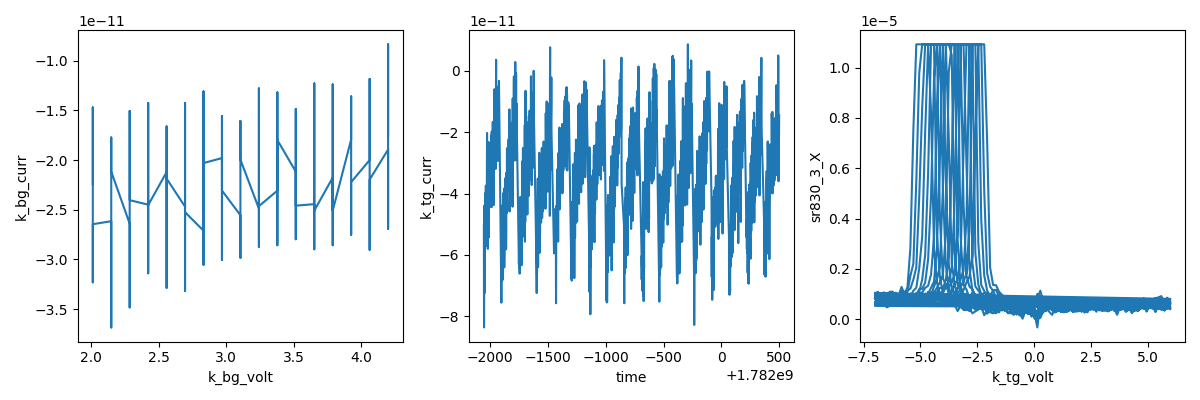

2026-06-20 17:08:20,859 [INFO] Completed in 0h 42m 38s
2026-06-20 17:08:20,859 [INFO] Data saved in C:\Users\toploader\measurements\aaron\zf1_toploader\data\3\data.tsv.gz
2026-06-20 17:08:20,921 [INFO] Ramping k_tg_volt: 6.0 -> 0
2026-06-20 17:08:28,553 [INFO] Ramping k_bg_volt: 4.2 -> 0


In [22]:
import numpy as np
import time

# --- preconditions ---
T = temperature(); B = magnet.field()
print(f"precond: T = {T*1e3:.1f} mK ; B = {B*1e3:.4f} mT (pristine) ; "
      f"k_tg={k_tg.volt():+.3f} k_bg={k_bg.volt():+.3f} V")
assert T < 0.1, f"T not at base: {T} K"
assert abs(B) < 0.005, f"field not pristine: {B} T"

# drive at validated 0.5 nA
sr830_1.amplitude(0.05)
meas_config["bias_voltage_1"] = sr830_1.amplitude()
assert abs(sr830_1.amplitude() - 0.05) < 1e-4, "drive not at 0.5 nA"
print(f"drive 0.5 nA OK (I_bias {meas_config['bias_voltage_1']/meas_config['bias_resistor']*1e9:.3f} nA)")

k_tg.nplci(1); k_bg.nplci(1)

# remainder rows of the same 61-pt BG grid; TG fast axis identical to run 2
bg_full = np.linspace(-4.0, 4.2, 61)
bg_slow = bg_full[44:]                  # +2.013 .. +4.2, 17 rows
tg_fast = np.linspace(-7.0, 6.0, 101)

meas_config["comment"] = (
    "Step-1 gatemap REMAINDER (stitches onto run 2 rows 0-43): BG slow [2.013,4.2] (17) "
    "x TG fast [-7,6] (101), B~0 pristine, drive 0.5 nA; sr4 dropped (unusable)"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('gatemap')
s.add_comment('zf1 Step-1 remainder; BG slow [2.013,4.2] (17), TG fast [-7,6] (101); stitch onto run 2; B~0; 0.5 nA')

s.ramp(k_bg.volt, bg_slow[0])
s.ramp(k_tg.volt, tg_fast[0])
time.sleep(10)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3):   # sr4 dropped (unusable + fewer SNAP reads)
    s.fp(lia.X).fp(lia.P)

s.plot(k_bg.volt, k_bg.curr)
s.plot('time', k_tg.curr)
s.plot(k_tg.volt, sr830_3.X)

try:
    s.megasweep(k_bg.volt, bg_slow, k_tg.volt, tg_fast, slow_delay=3, fast_delay=1)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)


## HERA — Step 2: bias spectroscopy point check at the lowest-Rxx point

Step-1 map (run 2+3) found **no SC candidate** — metallic Rxx everywhere, lowest 3×3-smoothed 4.4 Ω at (Vtg 0.02, Vbg 2.70 ; n≈+2.2e12 cm⁻², D≈−0.20 V/nm), nothing below 2 Ω. Per the constellation discipline I won't call not-SC from Rxx alone: this tests whether even the **best** (lowest-Rxx) point carries a supercurrent.

**What:** 1D dV/dI vs I_dc at the lowest-Rxx operating point. DC bias via `dc205_1` through the 100 MΩ resistor → I_dc = V_dc/1e8; sweep V_dc −1→+1 V = **I_dc −10→+10 nA** (101 pts, 0.2 nA steps). AC excitation stays 0.5 nA. **dV/dI = sr3 (4T) / I_ac** — read directly as the 4T Rxx channel (recipe's `sr830_1/sr830_4` ratio assumes a voltage-bias rig with a separate current monitor; on current-bias zf1 the AC current is constant and sr4 is dead → dV/dI ∝ sr830_3; logging this as a RECIPE FIX).

**Expected forks:** SC → dV/dI ≈ 0 below an Ic, rising sharply (a supercurrent lobe). Good normal metal → flat ohmic dV/dI ~4–5 Ω across all I_dc (the expected null here). If anything nonlinear appears, follow up with a round-trip (hysteresis) + reduced AC + a 2D bias-vs-n dome map.

**Price ~5 min.** `dc205_1.volt.step` raised to 0.02 V (bias through 100 MΩ is current-limited — large steps safe; keeps each move <0.1 V to avoid the DC205 10 s settle). `dc205_1.volt → 0` and gates parked in `finally` (device-card rule). **Preconditions** (asserted): T base; |B|<5 mT; drive 0.5 nA; gates/dc205 printed.


In [ ]:
import numpy as np

# --- preconditions ---
T = temperature(); B = magnet.field()
print(f"precond: T={T*1e3:.1f} mK ; B={B*1e3:.4f} mT ; k_tg={k_tg.volt():+.3f} k_bg={k_bg.volt():+.3f} V ; dc205={dc205_1.volt():+.3f} V")
assert T < 0.1, f"T not at base: {T} K"
assert abs(B) < 0.005, f"field not pristine: {B} T"
sr830_1.amplitude(0.05); meas_config["bias_voltage_1"] = sr830_1.amplitude()
assert abs(sr830_1.amplitude()-0.05) < 1e-4, "AC drive not 0.5 nA"

# operating point = global Rxx minimum from the Step-1 map
TG_OP, BG_OP = 0.02, 2.70
k_tg.nplci(1); k_bg.nplci(1)

# DC bias axis: V_dc/1e8 = I_dc ; -1..+1 V -> -10..+10 nA
dc205_1.volt.step = 0.02          # current-limited through 100 MΩ; <0.1 V/move avoids DC205 10 s settle
Vdc = np.linspace(-1.0, 1.0, 101)
Rbias = meas_config["bias_resistor"]

meas_config["comment"] = (
    f"bias-spectroscopy point check at Step-1 Rxx-min (Vtg={TG_OP}, Vbg={BG_OP}; n~+2.2e12, D~-0.2 V/nm); "
    f"dV/dI=sr3/I_ac; I_dc -10..+10 nA via dc205_1/100MOhm; AC 0.5 nA; B~0"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('bias-spectroscopy')
s.add_comment(f'point check @ Vtg={TG_OP} Vbg={BG_OP}; I_dc -10..+10 nA; AC 0.5 nA; B~0')

# move to operating point, zero DC bias, settle
s.ramp(k_bg.volt, BG_OP)
s.ramp(k_tg.volt, TG_OP)
s.ramp(dc205_1.volt, Vdc[0])
import time; time.sleep(10)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(dc205_1.volt)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)

s.plot(dc205_1.volt, sr830_3.X)   # dV/dI (4T) vs DC bias
s.plot(dc205_1.volt, sr830_1.X)   # AC current monitor

try:
    s.sweep(dc205_1.volt, Vdc, delay=1.5)
finally:
    s.ramp(dc205_1.volt, 0)        # device-card rule: dc205 -> 0 before ending
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)


## HERA — bias spectroscopy point check (CORRECTED — supersedes cell 40)

**Do not run cell 40** — it set `dc205_1.volt.step = 0.02`, now under a hard ban. This cell is identical except `volt.step` is left at its setup default (0.005 V). Logged the ban for the toploader card (session_notes).

**What:** 1D dV/dI vs I_dc at the Step-1 lowest-Rxx point (Vtg 0.02, Vbg 2.70; n≈+2.2e12 cm⁻², D≈−0.20 V/nm) — the confound test of whether even the best low-Rxx point carries a supercurrent. DC bias `dc205_1` through 100 MΩ → I_dc = V_dc/1e8; V_dc −1→+1 V = **I_dc −10→+10 nA** (101 pts). AC excitation 0.5 nA. **dV/dI read as `sr830_3` (4T, 30-31) / I_ac** (current-bias rig — sr830_1 is the current, sr830_4 is dead; recipe's sr1/sr4 ratio doesn't apply here).

**Forks:** SC → dV/dI ≈ 0 below an Ic, rising at the lobe edge. Good metal → flat ohmic ~4–5 Ω (expected). Anything nonlinear → round-trip + lower AC + a 2D bias-vs-n dome.

**Timing — note:** with `volt.step` left at 5 mV, the DC205's ~1 s fixed-ramp-per-set means the bias axis ramps slowly (≈ total volts traversed / 0.005 × ~1 s). Wall-clock is **uncertain, ~5–13 min**; I'll re-price from the run's first points. Interrupt if it drags and I'll trim the range. `dc205_1.volt → 0` + gates parked in `finally` (device-card rule). **Preconditions** asserted: T base; |B|<5 mT; drive 0.5 nA; gates/dc205 printed. No `volt.step` writes.


In [ ]:
import numpy as np
import time

# --- preconditions ---
T = temperature(); B = magnet.field()
print(f"precond: T={T*1e3:.1f} mK ; B={B*1e3:.4f} mT ; k_tg={k_tg.volt():+.3f} k_bg={k_bg.volt():+.3f} V ; dc205={dc205_1.volt():+.3f} V")
assert T < 0.1, f"T not at base: {T} K"
assert abs(B) < 0.005, f"field not pristine: {B} T"
sr830_1.amplitude(0.05); meas_config["bias_voltage_1"] = sr830_1.amplitude()
assert abs(sr830_1.amplitude()-0.05) < 1e-4, "AC drive not 0.5 nA"

# operating point = global Rxx minimum from the Step-1 map
TG_OP, BG_OP = 0.02, 2.70
k_tg.nplci(1); k_bg.nplci(1)

# DC bias axis: V_dc/1e8 = I_dc ; -1..+1 V -> -10..+10 nA
# NOTE: volt.step left at its setup default (0.005 V) — hard ban on changing it.
Vdc = np.linspace(-1.0, 1.0, 101)
Rbias = meas_config["bias_resistor"]

meas_config["comment"] = (
    f"bias-spectroscopy point check at Step-1 Rxx-min (Vtg={TG_OP}, Vbg={BG_OP}; n~+2.2e12, D~-0.2 V/nm); "
    f"dV/dI=sr3(4T)/I_ac; I_dc -10..+10 nA via dc205_1/100MOhm; AC 0.5 nA; B~0"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('bias-spectroscopy')
s.add_comment(f'point check @ Vtg={TG_OP} Vbg={BG_OP}; I_dc -10..+10 nA; AC 0.5 nA; B~0')

# move to operating point, zero DC bias, settle
s.ramp(k_bg.volt, BG_OP)
s.ramp(k_tg.volt, TG_OP)
s.ramp(dc205_1.volt, Vdc[0])
time.sleep(10)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(dc205_1.volt)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)

s.plot(dc205_1.volt, sr830_3.X)   # dV/dI (4T) vs DC bias
s.plot(dc205_1.volt, sr830_1.X)   # AC current monitor

try:
    s.sweep(dc205_1.volt, Vdc, delay=1.5)
finally:
    s.ramp(dc205_1.volt, 0)        # device-card rule: dc205 -> 0 before ending
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)


## HERA — bias spectroscopy point check (CORRECTED for sr2 — supersedes cells 40 & 42)

**Do not run cells 40 or 42** — both used sr3 as the 4T channel and the sr3 operating point. The 4T Rxx is sr2; redone here.

**Why still worth doing** with no candidate on the map: the Step-1 map ran at 0.5 nA AC. If a *fragile* superconductor had Ic < 0.5 nA, the AC drive would have exceeded Ic everywhere and shown the normal-state Rxx (no zero) — i.e. the map *cannot* rule out a sub-0.5 nA-Ic state. This point check, at **lower AC (0.25 nA)**, probes dV/dI vs I_dc near zero bias and is sensitive to a small Ic the map would miss. At the most-conducting point it's the decisive close: ohmic here ⇒ not-SC.

**What:** 1D dV/dI vs I_dc at the lowest-Rxx point **(Vtg −6.48, Vbg −3.73; n≈−8e12 cm⁻², D≈−0.12 V/nm)** — high hole density, the best-conducting metal (3.1 kΩ). **dV/dI = `sr830_2` (4T) / I_ac.** AC excitation lowered to **0.25 nA** (`sr830_1.amplitude` 0.05→0.025; sr2 SNR fine at 0.75 µV). DC bias `dc205_1` through 100 MΩ; V_dc −0.5→+0.5 V = **I_dc −5→+5 nA** (101 pts, 0.1 nA steps — fine near zero).

**Forks:** SC → dV/dI dips toward 0 below an Ic. Metal → flat ohmic ~3 kΩ across all I_dc (expected). Structure → extend range, round-trip, then a 2D bias-vs-n dome.

**No `volt.step` change** (default 5 mV). DC205 ramps slowly at that step → wall-clock **~5–8 min** (smaller ±5 nA range to keep it short); I'll re-price from the first points, interrupt if it drags. `dc205_1.volt → 0` + gates parked in `finally`. **Preconditions** asserted: T base; |B|<5 mT; AC 0.25 nA; gates/dc205 printed.


In [ ]:
import numpy as np
import time

# --- preconditions ---
T = temperature(); B = magnet.field()
print(f"precond: T={T*1e3:.1f} mK ; B={B*1e3:.4f} mT ; k_tg={k_tg.volt():+.3f} k_bg={k_bg.volt():+.3f} V ; dc205={dc205_1.volt():+.3f} V")
assert T < 0.1, f"T not at base: {T} K"
assert abs(B) < 0.005, f"field not pristine: {B} T"

# AC excitation lowered to 0.25 nA to catch a fragile sub-0.5 nA Ic (NOT a volt.step change)
sr830_1.amplitude(0.025); meas_config["bias_voltage_1"] = sr830_1.amplitude()
print(f"AC drive {sr830_1.amplitude()*1e3:.0f} mV -> I_ac {meas_config['bias_voltage_1']/meas_config['bias_resistor']*1e9:.3f} nA")
assert abs(sr830_1.amplitude()-0.025) < 1e-4

# operating point = lowest-Rxx point on the sr2 4T map (best-conducting metal)
TG_OP, BG_OP = -6.48, -3.73
k_tg.nplci(1); k_bg.nplci(1)

# DC bias: V_dc/1e8 = I_dc ; -0.5..+0.5 V -> -5..+5 nA. volt.step left at default (hard ban).
Vdc = np.linspace(-0.5, 0.5, 101)

meas_config["comment"] = (
    f"bias-spectroscopy point check at sr2 Rxx-min (Vtg={TG_OP}, Vbg={BG_OP}; n~-8e12, D~-0.12 V/nm); "
    f"dV/dI=sr2(4T)/I_ac; I_dc -5..+5 nA via dc205_1/100MOhm; AC 0.25 nA; B~0"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('bias-spectroscopy')
s.add_comment(f'point check @ Vtg={TG_OP} Vbg={BG_OP}; I_dc -5..+5 nA; AC 0.25 nA; dV/dI=sr2; B~0')

s.ramp(k_bg.volt, BG_OP)
s.ramp(k_tg.volt, TG_OP)
s.ramp(dc205_1.volt, Vdc[0])
time.sleep(10)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(dc205_1.volt)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)

s.plot(dc205_1.volt, sr830_2.X)   # dV/dI (4T = sr2) vs DC bias
s.plot(dc205_1.volt, sr830_1.X)   # AC current monitor

try:
    s.sweep(dc205_1.volt, Vdc, delay=1.5)
finally:
    s.ramp(dc205_1.volt, 0)
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)


## HERA — effective-zero-field calibration (trapped-flux hint)

**Why this, not the bias-spec (hold cell 44).** My Step-1 map was taken at `magnet.field()≈0` — the *controller's* nominal zero. With the device card's **~2 mT trapped flux**, the sample actually sat at ~2 mT, not true zero. These BLG-WSe₂ proximity SCs live on the mT scale (refs sweep B_eff 0–3 mT), so a fragile SC could have been **suppressed across the whole map** → "no candidate" is not yet safe. The true operating field is the SC's own field maximum (≈ where the trapped flux is cancelled), not the controller's zero (investigation Step 3).

**What:** Rxx(B) at a moderate hole point **(Vtg −4.79, Vbg 1.06; n≈−2.5e12 cm⁻², D≈−0.4 V/nm; 4.7 kΩ, clear of the k_bg≈0 feature)**. Two **one-sided** segments per the session field discipline (never increase |B| through 0 while measuring): ramp to **−8 mT**, settle, sweep **−8→0**; then ramp to **+8 mT**, settle, sweep **+8→0**. Stitched → Rxx(B) over ±8 mT bracketing zero from both sides. 0.2 mT steps (41 pts/segment), AC 0.5 nA, Rxx = `sr830_2`.

**Reads:** (1) the **MR symmetry center / weak-(anti)localization feature = true B=0** → the trapped-flux offset (transfers to the whole map); (2) a sharp **Rxx dip at the effective zero ⇒ a field-suppressed SC** revealed; (3) magnet ramp_rate (read live) + thermal settle behavior, to price a follow-up 2D Rxx(n,B) search.

**Forks:** dip at B_eff → SC candidate found, characterize (bias-spec/Fraunhofer at B_eff). Smooth symmetric MR, no dip → no SC at this (n,D); next is a 2D (n,B) search across density at the corrected zero before any not-SC call.

**Discipline/safety:** |B|≤8 mT ≪ 100 mT cap (validator-guarded). Heating is worst near 0 (flux-motion loss) — `temperature` is fp'd + the per-point delay=1 lets it settle; watch the live MR + T. No `volt.step` change. First magnet energisation this session — if interrupted mid-ramp the supply keeps ramping to its last target (re-issue `magnet.field(0)` to recover). **~6–8 min.** Magnet ends at 0; gates stay at the op point for the follow-up.


In [ ]:
import numpy as np
import time

# --- preconditions ---
T = temperature()
print(f"precond: T={T*1e3:.1f} mK ; B now={magnet.field()*1e3:.4f} mT ; ramp_rate={magnet.ramp_rate()} T/s")
print(f"precond: k_tg={k_tg.volt():+.3f} k_bg={k_bg.volt():+.3f} V")
assert T < 0.1, f"T not at base: {T} K"

# AC excitation 0.5 nA (clean MR for true-zero; re-probe any dip at lower AC)
sr830_1.amplitude(0.05); meas_config["bias_voltage_1"] = sr830_1.amplitude()

TG_OP, BG_OP = -4.79, 1.06       # n~-2.5e12 cm^-2, D~-0.4 V/nm (moderate hole, finite D)
B_EXT = 0.008                    # 8 mT extreme; <<100 mT cap
nB = 41                          # 0.2 mT steps per segment
k_tg.nplci(1); k_bg.nplci(1)

meas_config["comment"] = (
    f"effective-zero-field cal @ (Vtg={TG_OP},Vbg={BG_OP}; n~-2.5e12, D~-0.4); "
    f"two one-sided B-sweeps +/-8mT->0; trapped-flux ~2mT; Rxx=sr2(4T); AC 0.5 nA"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('field-sweep-1d')
s.add_comment(f'eff-zero-field cal; (Vtg,Vbg)=({TG_OP},{BG_OP}) n=-2.5e12 D=-0.4; one-sided -8/+8mT->0; trapped-flux search')

# gates to operating point (DC bias source already at 0)
s.ramp(k_tg.volt, TG_OP)
s.ramp(k_bg.volt, BG_OP)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)
s.plot(magnet.field, sr830_2.X)   # live MR = 4T Rxx vs B
s.plot('time', k_tg.curr)

# --- segment A: ramp to -8 mT (away from 0), settle, measure-sweep -8 -> 0 ---
s.ramp(magnet.field, -B_EXT)
time.sleep(60)                    # post-ramp thermal settle (first field excursion; monitor T)
s.sweep(magnet.field, np.linspace(-B_EXT, 0.0, nB), delay=1)

# --- segment B: ramp to +8 mT (ramp only, not measured), settle, measure-sweep +8 -> 0 ---
s.ramp(magnet.field, +B_EXT)
time.sleep(60)
s.sweep(magnet.field, np.linspace(+B_EXT, 0.0, nB), delay=1)

# leave magnet at 0 (segment B ends there); gates stay at op point for the follow-up
print("done; magnet at", magnet.field(), "T")


In [24]:
sr830_6.amplitude()

0.004

## HERA — verify rotator-servo lock-ins sr830_6 (θ) / sr830_7 (φ) excitations are off

Read-only. The rotator (ANC350 θ/φ) is blocklisted this session, so sr830_6/7 sine outputs should be at the SR830 minimum (≈4 mV) — effectively off — so they don't inject into the transport noise floor (θ/φ sin-out off is the documented noise-reduction step on this rig). **Run this before the effective-zero field sweep**; if either reads a large amplitude, we turn it down first (cleaner floor for the fragile-SC dip search). No writes.


In [25]:
# Read-only check of the rotator-servo lock-ins' excitations.
for ch, role in [(sr830_6, "theta"), (sr830_7, "phi"), (sr830_1, "current-drive (ref)")]:
    try:
        amp = ch.amplitude()
        freq = ch.frequency()
        try:
            ref = ch.reference_source()
        except Exception:
            ref = "?"
        flag = "OFF (min)" if amp <= 0.0051 else ">>> EXCITATION ON <<<"
        print(f"{ch.name} ({role}): amplitude={amp*1e3:.1f} mV  freq={freq:.3f} Hz  ref={ref}   {flag}")
    except Exception as e:
        print(f"{ch.name} ({role}): read error -> {e!r}")


sr830_6 (theta): amplitude=4.0 mV  freq=13.777 Hz  ref=internal   OFF (min)
sr830_7 (phi): amplitude=4.0 mV  freq=17.111 Hz  ref=internal   OFF (min)
sr830_1 (current-drive (ref)): amplitude=50.0 mV  freq=7.777 Hz  ref=internal   >>> EXCITATION ON <<<


## HERA — high-res zoom: V_bg>0 / V_tg<0 quadrant (SC re-investigation)

Per operator: re-investigate SC in the **V_bg positive, V_tg negative** quadrant — the large-negative-D region where BLG-WSe₂ Ising-SOC proximity SC is expected. The coarse Step-1 map (0.13 V) showed only metal + CNP ridge here; this zoom (**0.07 V grid, ~2× finer**) tests whether a narrow SC dome was stepped over. 4T Rxx = **sr830_2** (corrected channel); θ/φ excitations off (clean floor); drive 0.5 nA.

**Box:** V_tg fast **[−7, 0]** (101 pts, 0.07 V) × V_bg slow **[0, +4.2]** (61 pts, 0.07 V). Megasweep, slow_delay=3 / fast_delay=1. Reads trimmed to sr1/sr2 (+ gates, T) to cut per-point time. The CNP ridge crosses this box (Vtg_cnp = −1.19·Vbg+0.08); it covers both sides at large negative D.

**⚠ Field caveat:** taken at `magnet.field()≈0` = ~2 mT at the sample (trapped flux). This is an **under-resolution check only** — a *field-suppressed* fragile SC stays hidden even here. If clean, the effective-zero-field search is the decisive next step (or I re-run this zoom at the effective zero).

**Price:** 6161 pts. From the measured megasweep rate (~1.3–1.5 s/pt with trimmed reads) → **~2–2.5 hr**. **Checkpoint @ ~12 BG rows (~25–30 min):** I'll read the partial sr2 map for any low-Rxx feature; continue / fine-zoom on a hit / abandon if clearly featureless. `hera-watch` armed.

**Preconditions** (asserted): T base; |B|<5 mT; drive 0.5 nA; gates printed. No magnet move; no `volt.step` change. Leakage corners (TG −7, BG +4.2) already validated clean. Gates park to 0 at end.


precond: T=33.7 mK ; B=-0.0075 mT (nominal zero; ~2 mT trapped at sample) ; k_tg=+0.000 k_bg=+0.000 V
2026-06-20 20:04:56,624 [INFO] Ramping k_bg_volt: 0.0 -> 0.0
2026-06-20 20:04:56,695 [INFO] Ramping k_tg_volt: 0.0 -> -7.0
2026-06-20 20:05:15,782 [INFO] Starting megasweep with ID 4
2026-06-20 20:05:15,783 [INFO] Minimum duration 1h 45m 44s


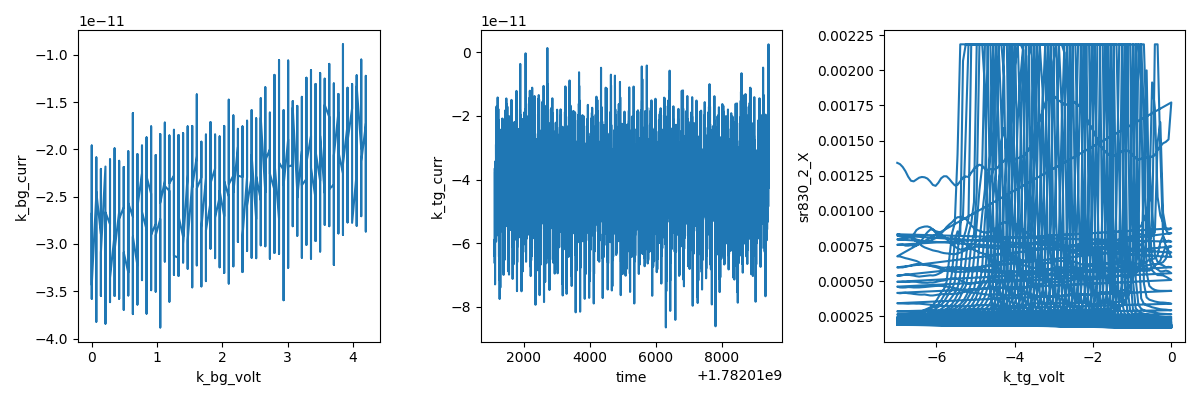

2026-06-20 22:23:43,662 [INFO] Completed in 2h 18m 27s
2026-06-20 22:23:43,663 [INFO] Data saved in C:\Users\toploader\measurements\aaron\zf1_toploader\data\4\data.tsv.gz
2026-06-20 22:23:43,724 [INFO] Ramping k_tg_volt: 0.0 -> 0
2026-06-20 22:23:43,787 [INFO] Ramping k_bg_volt: 4.2 -> 0


In [26]:
import numpy as np
import time

# --- preconditions ---
T = temperature(); B = magnet.field()
print(f"precond: T={T*1e3:.1f} mK ; B={B*1e3:.4f} mT (nominal zero; ~2 mT trapped at sample) ; "
      f"k_tg={k_tg.volt():+.3f} k_bg={k_bg.volt():+.3f} V")
assert T < 0.1, f"T not at base: {T} K"
assert abs(B) < 0.005, f"field unexpectedly finite: {B} T"
sr830_1.amplitude(0.05); meas_config["bias_voltage_1"] = sr830_1.amplitude()
assert abs(sr830_1.amplitude()-0.05) < 1e-4, "drive not 0.5 nA"

k_tg.nplci(1); k_bg.nplci(1)

# zoom box: V_bg>0 / V_tg<0 quadrant, 0.07 V grid
bg_slow = np.linspace(0.0, 4.2, 61)    # slow (0.07 V)
tg_fast = np.linspace(-7.0, 0.0, 101)  # fast (0.07 V)

meas_config["comment"] = (
    "SC re-investigation zoom: V_bg>0/V_tg<0 quadrant (large -D), BG slow [0,4.2] x TG fast [-7,0], "
    "0.07 V grid, Rxx=sr2(4T), 0.5 nA, B~0 (nominal; ~2 mT trapped)"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('gatemap')
s.add_comment('SC zoom V_bg>0/V_tg<0; BG slow [0,4.2] (61), TG fast [-7,0] (101); 0.07 V; Rxx=sr2; B~0 nominal')

s.ramp(k_bg.volt, bg_slow[0])
s.ramp(k_tg.volt, tg_fast[0])
time.sleep(10)

# trimmed reads: sr1 (current) + sr2 (4T Rxx) + gates + T
s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2):
    s.fp(lia.X).fp(lia.P)

s.plot(k_bg.volt, k_bg.curr)
s.plot('time', k_tg.curr)
s.plot(k_tg.volt, sr830_2.X)   # 4T Rxx along the fast axis

try:
    s.megasweep(k_bg.volt, bg_slow, k_tg.volt, tg_fast, slow_delay=3, fast_delay=1)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)


In [28]:
def calc_time(vec1, vec2, delay):
    return len(vec1)*len(vec2)*delay

import scipy.constants as cst

cst_epsilon0 = cst.epsilon_0
cst_e = cst.e
cst_h = cst.h
cst_phi0 = cst_h/(2*cst_e)
cst_kappa_SiO2 = 3.9
cst_kappa_hBN = 3

def calc_ctg(t_tg):
    """
    Calculates area capacitance for a top gate
    """
    return cst_epsilon0*cst_kappa_hBN/t_tg

def calc_cbg(t_bg, t_bgSiO2):
    """
    Calculates area capacitance for a back gate
    For a metal back gate, set t_bgSiO2 = 0
    """
    return cst_epsilon0*1/(t_bg/cst_kappa_hBN + t_bgSiO2/cst_kappa_SiO2)

def calc_nD(V_tg, V_bg, c_tg, c_bg, n_offset=0, D_offset = 0):
    n = (1/cst_e) * (c_tg*V_tg  + c_bg*V_bg) + n_offset
    D = 0.5*(c_tg*V_tg - c_bg*V_bg)*1/cst_epsilon0 + D_offset
    return n, D

def calc_tb(n, D, c_tg, c_bg, n_offset, D_offset):
    """
    Calculate gate voltages assuming density and displacement field
    Density is in SI units, D (actually D/epsilon_0) is V/m
    """
    V_tg = (1/(2*c_tg)) * ((n - n_offset)*cst_e + 2*cst_epsilon0*(D - D_offset))
    V_bg = (1/(2*c_bg)) * ((n - n_offset)*cst_e - 2*cst_epsilon0*(D - D_offset))
    return V_tg, V_bg

def conv_offsets_to_gate(c_tg, c_bg, n_offset, D_offset):
    """
    Convert n, D offsets to offset voltages
    """
    V_tg_offset = (2*cst_epsilon0*D_offset + cst_e*n_offset)/(2*c_tg)
    V_bg_offset = (2*cst_epsilon0*D_offset - cst_e*n_offset)/(2*c_bg)
    return V_tg_offset, V_bg_offset
    
def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

2026-06-20 23:28:51,379 [INFO] Starting multimegasweep with ID 5
2026-06-20 23:28:51,381 [INFO] Minimum duration 0h 1m 1s


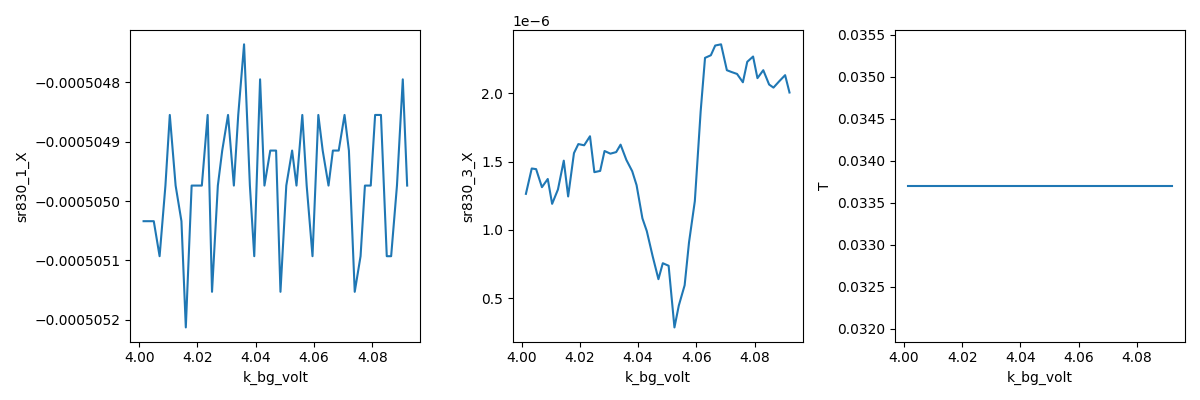

2026-06-20 23:30:13,298 [INFO] Completed in 0h 1m 21s
2026-06-20 23:30:13,298 [INFO] Data saved in C:\Users\toploader\measurements\aaron\zf1_toploader\data\5\data.tsv.gz

Excitations restored.


In [33]:
# Density polygon — same SC band as in-plane Hc2 work
N_MIN, N_MAX        = -0.55e16, -0.40e16
N_PTS_DENSITY       = 51
D_FIXED             = -0.650e9
FAST_DELAY          = 1.2

t_bg = 20e-9; t_tg = 1.18 * t_bg
c_tg = calc_ctg(t_tg); c_bg = calc_cbg(t_bg, 0)
n_vec = np.linspace(N_MIN, N_MAX, N_PTS_DENSITY)
vtg, vbg = calc_tb(n_vec, D_FIXED, c_tg, c_bg, n_offset=0, D_offset=0)
vtg, vbg = sanitize_tg_bg(vtg, vbg, [-7, 6], [-4, 4.2])
B_TARGET = 0

try:
    # === Step 2: density sweep at B = 0 ===
    meas_config = {
        "sr1": "5 - 4",   "sr1_gain": -1e6, "sr2": "5 - 4",   "sr2_gain": 1e2,
        "sr3": "30 - 31", "sr3_gain": 1e2,  "bias_resistor": 1e8,
        "bias_voltage_1": sr830_1.amplitude(),
        "lockin_freq_1" : sr830_1.frequency(),
        "B_target_T"               : float(B_TARGET),
        "Beff_perp_mT_estimate"    : -2.43,
        "chip_perp_at_B0_mT_estimate": +2.43,
        "purpose"                  : "density at B=0 at perp — uncompensated trapped flux test",
    }
    s = sweep.AsyncStation(meas_config)
    s.add_comment("perp-density-at-Bzero")
    for p in [sr830_1.X, sr830_1.P, sr830_2.X, sr830_2.P, sr830_3.X, sr830_3.P,
              sr830_6.X, sr830_6.P, sr830_7.X, sr830_7.P,
              k_bg.volt, k_bg.curr, k_tg.volt, k_tg.curr, temperature, magnet.field]:
        s.fp(p)
    for p in [sr830_1.X, sr830_3.X, temperature]:
        s.plot(k_bg.volt, p)

    s.multimegasweep(
        slow_params=[magnet.field], slow_v_list=[[B_TARGET]],
        fast_params=[k_tg.volt, k_bg.volt], fast_v_list=[vtg, vbg],
        slow_delay=0, fast_delay=FAST_DELAY,
    )


finally:
    # sr830_6.amplitude(EXCITATION_FULL_V)
    # sr830_7.amplitude(EXCITATION_FULL_V_PHI)
    print(f"\nExcitations restored.")


2026-06-20 23:37:28,940 [INFO] Starting multimegasweep with ID 6
2026-06-20 23:37:28,941 [INFO] Minimum duration 0h 1m 1s


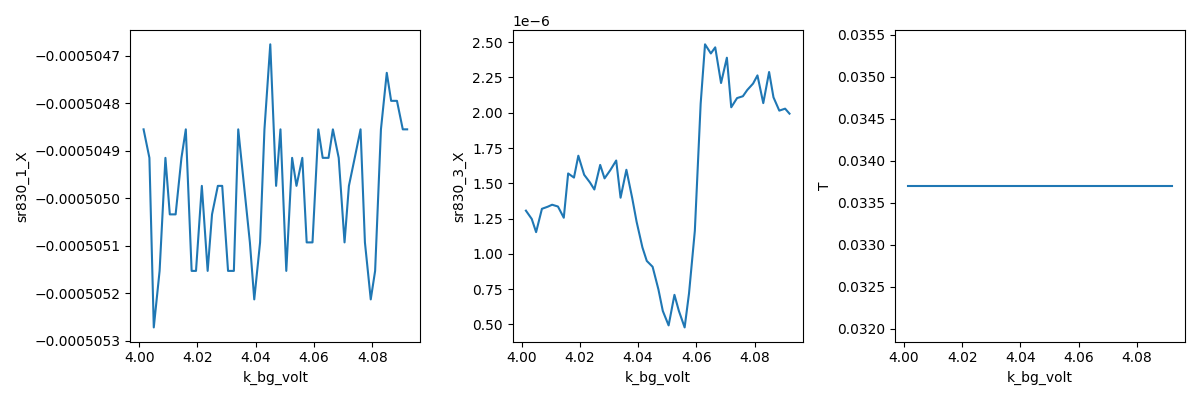

2026-06-20 23:38:41,039 [INFO] Completed in 0h 1m 11s
2026-06-20 23:38:41,040 [INFO] Data saved in C:\Users\toploader\measurements\aaron\zf1_toploader\data\6\data.tsv.gz

Excitations restored.


In [35]:
# Density polygon — same SC band as in-plane Hc2 work
N_MIN, N_MAX        = -0.55e16, -0.40e16
N_PTS_DENSITY       = 51
D_FIXED             = -0.650e9
FAST_DELAY          = 1.2

t_bg = 20e-9; t_tg = 1.18 * t_bg
c_tg = calc_ctg(t_tg); c_bg = calc_cbg(t_bg, 0)
n_vec = np.linspace(N_MIN, N_MAX, N_PTS_DENSITY)
vtg, vbg = calc_tb(n_vec, D_FIXED, c_tg, c_bg, n_offset=0, D_offset=0)
vtg, vbg = sanitize_tg_bg(vtg, vbg, [-7, 6], [-4, 4.2])
B_TARGET = 0
B_COMPENSATION = 0.00243


magnet.field(B_COMPENSATION)


try:
    # === Step 2: density sweep at B = 0 ===
    meas_config = {
        "sr1": "5 - 4",   "sr1_gain": -1e6, "sr2": "5 - 4",   "sr2_gain": 1e2,
        "sr3": "30 - 31", "sr3_gain": 1e2,  "bias_resistor": 1e8,
        "bias_voltage_1": sr830_1.amplitude(),
        "lockin_freq_1" : sr830_1.frequency(),
        "B_target_T"               : float(B_TARGET),
        "Beff_perp_mT_estimate"    : -2.43,
        "chip_perp_at_B0_mT_estimate": +2.43,
        "purpose"                  : "density at B=0 at perp — uncompensated trapped flux test",
    }
    s = sweep.AsyncStation(meas_config)
    s.add_comment("perp-density-at-Bzero")
    for p in [sr830_1.X, sr830_1.P, sr830_2.X, sr830_2.P, sr830_3.X, sr830_3.P,
              sr830_6.X, sr830_6.P, sr830_7.X, sr830_7.P,
              k_bg.volt, k_bg.curr, k_tg.volt, k_tg.curr, temperature, magnet.field]:
        s.fp(p)
    for p in [sr830_1.X, sr830_3.X, temperature]:
        s.plot(k_bg.volt, p)

    s.multimegasweep(
        slow_params=[magnet.field], slow_v_list=[[B_TARGET]],
        fast_params=[k_tg.volt, k_bg.volt], fast_v_list=[vtg, vbg],
        slow_delay=0, fast_delay=FAST_DELAY,
    )


finally:
    # sr830_6.amplitude(EXCITATION_FULL_V)
    # sr830_7.amplitude(EXCITATION_FULL_V_PHI)
    print(f"\nExcitations restored.")


2026-06-20 23:39:23,795 [INFO] Starting multimegasweep with ID 7
2026-06-20 23:39:23,795 [INFO] Minimum duration 0h 1m 1s


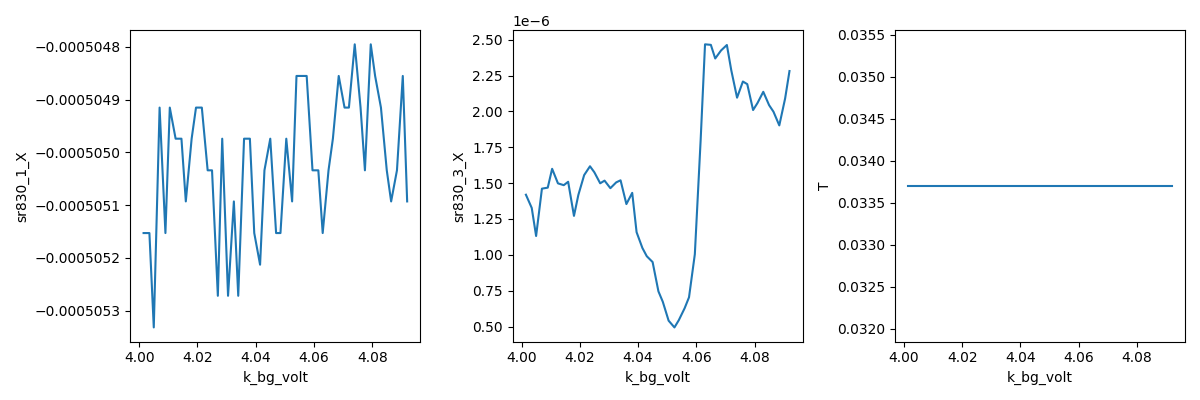

2026-06-20 23:40:35,902 [INFO] Completed in 0h 1m 11s
2026-06-20 23:40:35,903 [INFO] Data saved in C:\Users\toploader\measurements\aaron\zf1_toploader\data\7\data.tsv.gz

Excitations restored.


In [36]:
# Density polygon — same SC band as in-plane Hc2 work
N_MIN, N_MAX        = -0.55e16, -0.40e16
N_PTS_DENSITY       = 51
D_FIXED             = -0.650e9
FAST_DELAY          = 1.2

t_bg = 20e-9; t_tg = 1.18 * t_bg
c_tg = calc_ctg(t_tg); c_bg = calc_cbg(t_bg, 0)
n_vec = np.linspace(N_MIN, N_MAX, N_PTS_DENSITY)
vtg, vbg = calc_tb(n_vec, D_FIXED, c_tg, c_bg, n_offset=0, D_offset=0)
vtg, vbg = sanitize_tg_bg(vtg, vbg, [-7, 6], [-4, 4.2])
B_TARGET = 0
B_COMPENSATION = 0.00243


magnet.field(-B_COMPENSATION)


try:
    # === Step 2: density sweep at B = 0 ===
    meas_config = {
        "sr1": "5 - 4",   "sr1_gain": -1e6, "sr2": "5 - 4",   "sr2_gain": 1e2,
        "sr3": "30 - 31", "sr3_gain": 1e2,  "bias_resistor": 1e8,
        "bias_voltage_1": sr830_1.amplitude(),
        "lockin_freq_1" : sr830_1.frequency(),
        "B_target_T"               : float(B_TARGET),
        "Beff_perp_mT_estimate"    : -2.43,
        "chip_perp_at_B0_mT_estimate": +2.43,
        "purpose"                  : "density at B=0 at perp — uncompensated trapped flux test",
    }
    s = sweep.AsyncStation(meas_config)
    s.add_comment("perp-density-at-Bzero")
    for p in [sr830_1.X, sr830_1.P, sr830_2.X, sr830_2.P, sr830_3.X, sr830_3.P,
              sr830_6.X, sr830_6.P, sr830_7.X, sr830_7.P,
              k_bg.volt, k_bg.curr, k_tg.volt, k_tg.curr, temperature, magnet.field]:
        s.fp(p)
    for p in [sr830_1.X, sr830_3.X, temperature]:
        s.plot(k_bg.volt, p)

    s.multimegasweep(
        slow_params=[magnet.field], slow_v_list=[[B_TARGET]],
        fast_params=[k_tg.volt, k_bg.volt], fast_v_list=[vtg, vbg],
        slow_delay=0, fast_delay=FAST_DELAY,
    )


finally:
    # sr830_6.amplitude(EXCITATION_FULL_V)
    # sr830_7.amplitude(EXCITATION_FULL_V_PHI)
    print(f"\nExcitations restored.")


## HERA — rasterized (n,D) zoom to map the SC-candidate extent

Map the extent of the candidate state around the run-5 dip (n ≈ −0.465 e12 cm⁻², D ≈ −0.65 V/nm) at the sampling density needed to resolve it (the dip FWHM is ~0.027 e12 / ~0.017 V — a uniform raster at that spacing over the quadrant is impractical, so this is a *tight* rasterized polygon focused on the dip).

**Method (`nD-map`):** `sweep.raster.rasterize` a rectangle in **(n,D)** → project to gates via `calculate_gate_voltages` (device hBN dtg 23.6 / dbg 20 nm, κ=3) → `sanitize_tg_bg` to the validators. Caps are data-validated (CNP slope 1.19), so the (n,D) projection is trustworthy.

**Box:** n ∈ [−0.63, −0.28] e12 × D ∈ [−0.67, −0.50] V/nm, **71×35 raster ≈ 0.005 e12 × 0.005 V/nm** (~5 pts across the dip FWHM — maximizing sampling here). 2380 pts, **1.4% clipped** at V_bg=4.2 (preview: `hera_scratch/nd_design.png`). **Both `sr830_2` (Rxx) and `sr830_3` (the sharp marker)** read.

**Reach caveat:** V_bg=4.2 caps the negative-D edge at ~−0.67 V/nm — the dip sits right at it, so the dome's *more-negative-D* side is gate-inaccessible at this density; the map extends toward less-negative D (where it's open).
**Field caveat:** at B=0 nominal (~2 mT trapped), same as run 5 — this maps the *as-found* extent; a field-suppressed SC would be deeper/wider at the effective zero (the field follow-up).

**Price ~50 min** (2347 in-range pts × ~1.3 s, multisweep delay 1.2). **Checkpoint ~20 min:** the dip's D is the first raster rows, so it appears early — I'll confirm it reproduces in 2D and read its (n,D) shape. Drive 0.5 nA, no `volt.step` change, gates park at end. Preconditions asserted (T base, |B|<5 mT, drive).


In [ ]:
import numpy as np
import time
from sweep import raster
from sharpelab_nb.gates import calculate_gate_voltages

# --- preconditions ---
T = temperature(); B = magnet.field()
print(f"precond: T={T*1e3:.1f} mK ; B={B*1e3:.4f} mT (nominal zero; ~2 mT trapped) ; "
      f"k_tg={k_tg.volt():+.3f} k_bg={k_bg.volt():+.3f}")
assert T < 0.1, f"T not at base: {T} K"
assert abs(B) < 0.005, f"field not pristine: {B} T"
sr830_1.amplitude(0.05); meas_config["bias_voltage_1"] = sr830_1.amplitude()
assert abs(sr830_1.amplitude()-0.05) < 1e-4, "drive not 0.5 nA"
k_tg.nplci(1); k_bg.nplci(1)

# --- rasterized (n,D) box around the dip; n[e12 cm^-2], D[V/nm] ---
DTG, DBG, EP = 23.6, 20.0, 3.0       # device hBN thicknesses (nm) + kappa (device card)
N_LO, N_HI = -0.63, -0.28
D_LO, D_HI = -0.67, -0.50            # negative-D edge capped by Vbg<=4.2
NX, NY = 71, 35                       # ~0.005 e12 x ~0.005 V/nm
verts = np.array([[N_LO,D_LO],[N_HI,D_LO],[N_HI,D_HI],[N_LO,D_HI],[N_LO,D_LO]])
ns, Ds = raster.rasterize(verts, NX, NY, 0)
vtg_vec, vbg_vec = calculate_gate_voltages(ns, Ds, dtg=DTG, dbg=DBG, ep=EP)
vtg_new, vbg_new = sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims)
print(f"raster {len(ns)} pts -> in-validator {len(vtg_new)} (clipped {len(ns)-len(vtg_new)}, "
      f"{100*(1-len(vtg_new)/len(ns)):.1f}%)")
print(f"gate extent: Vtg {vtg_new.min():.3f}..{vtg_new.max():.3f} ; Vbg {vbg_new.min():.3f}..{vbg_new.max():.3f}")

meas_config["comment"] = (
    "nD-map SC-extent zoom @ run-5 dip (n=-0.465e12, D=-0.65 V/nm); "
    "n[-0.63,-0.28] x D[-0.67,-0.50], 71x35 raster; Rxx=sr2 (+sr3 marker); 0.5 nA; B~0 nominal"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('nD-map')
s.add_comment('SC-extent zoom @ dip; n[-0.63,-0.28]e12 x D[-0.67,-0.50]V/nm; 71x35; B~0 nominal; 0.5 nA; sr2+sr3')

s.ramp(k_tg.volt, vtg_new[0])
s.ramp(k_bg.volt, vbg_new[0])
time.sleep(10)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)
s.plot(k_bg.volt, k_bg.curr)
s.plot('time', k_tg.curr)
s.plot(k_bg.volt, sr830_2.X)   # 4T Rxx
s.plot(k_bg.volt, sr830_3.X)   # sharp marker

try:
    s.multisweep([k_tg.volt, k_bg.volt], [vtg_new, vbg_new], delay=1.2)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)


## HERA — rasterized (n,D) SC-extent map, expanded to ~8 h (supersedes cell 60)

Expanded per operator: density **n ∈ [−0.70, −0.10] e12 cm⁻²**, **D from the max accessible negative (V_bg=4.2 limit) up to −0.45 V/nm**, resolution sized for **~8 h**. **Run this, not cell 60.**

**Grid:** 240×100 raster ≈ **0.0025 e12 × 0.0025 V/nm** (~11 pts across the dip's 0.027 e12 FWHM — high oversampling). 23,661 raster pts → **20,572 in-validator**; the 13% "clip" is the gate-inaccessible max-(−D) corner beyond V_bg=4.2 (the accessible −D edge runs −0.69→−0.635 across n — preview `hera_scratch/nd_design2.png`, run-5 dip sits right on it). Method = `sweep.raster.rasterize` → `calculate_gate_voltages` (dtg 23.6 / dbg 20 nm, κ=3) → `sanitize_tg_bg`; caps data-validated. Both **sr2 (Rxx)** and **sr3 (sharp marker)** read.

**Time ~8 h** (20,572 pts × ~1.4 s/pt est; multisweep delay 1.2). Estimate has ±0.5 h slack on the per-point rate — I'll **re-price from the actual rate at the first checkpoint**; interrupt anytime (partial data is readable). Raster order: D ascends from −0.70, so the **dip's D (−0.65) lands ~20% in (~1.6 h)**; the max-(−D) region is mapped first.

**Checkpoints:** ~45 min (leakage clean, channels alive, time re-priced) and ~2 h (dip region reproduces in 2D). `hera-watch` armed.

**Field caveat:** B=0 nominal (~2 mT trapped), same as run 5 — maps the *as-found* extent; a field-suppressed SC would be deeper/wider at the effective zero (the field follow-up at the dip remains the decisive SC test). Drive 0.5 nA, no `volt.step` change, gates park at end. Preconditions asserted.


precond: T=33.7 mK ; B=0.0093 mT (nominal zero; ~2 mT trapped) ; k_tg=-5.398 k_bg=+4.092
raster 23661 -> in-validator 20572 (clipped 3089 = 13.1%, gate-inaccessible max-(-D) corner)
gate extent: Vtg -5.944..-3.611 ; Vbg 2.579..4.200
est time @1.4 s/pt: 8.0 h
2026-06-21 00:03:31,111 [INFO] Ramping k_tg_volt: -5.398 -> -5.9435031036845904
2026-06-21 00:03:31,868 [INFO] Ramping k_bg_volt: 4.092 -> 4.195456195302394
2026-06-21 00:03:42,006 [INFO] Starting multisweep with ID 8
2026-06-21 00:03:42,007 [INFO] Minimum duration 6h 51m 26s


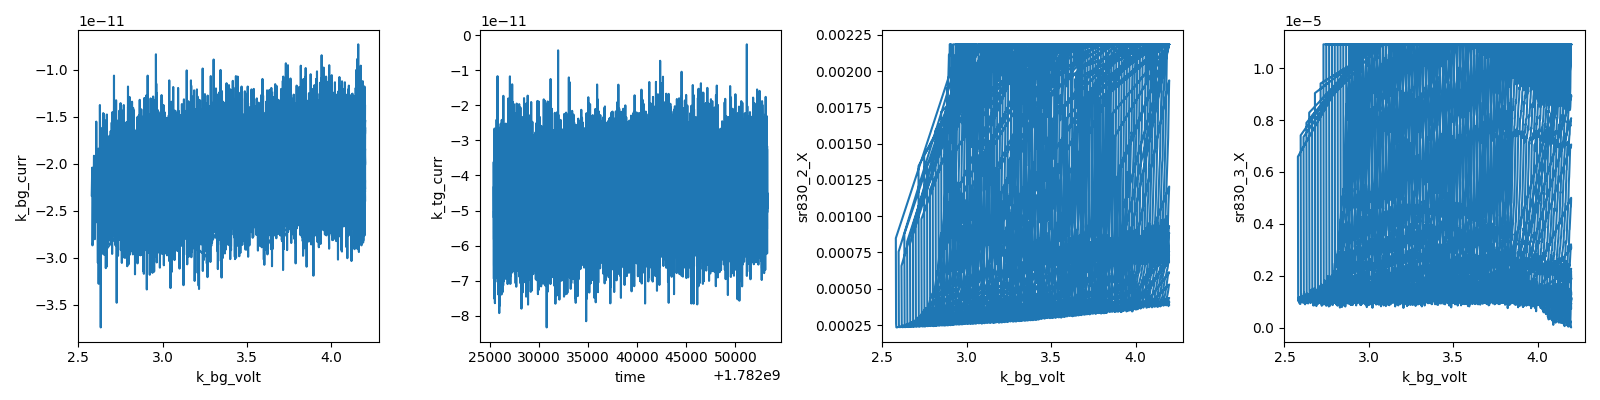

2026-06-21 07:47:20,215 [INFO] Completed in 7h 43m 37s
2026-06-21 07:47:20,215 [INFO] Data saved in C:\Users\toploader\measurements\aaron\zf1_toploader\data\8\data.tsv.gz
2026-06-21 07:47:20,277 [INFO] Ramping k_tg_volt: -3.611 -> 0
2026-06-21 07:47:24,944 [INFO] Ramping k_bg_volt: 2.9395 -> 0


In [37]:
import numpy as np
import time
from sweep import raster
from sharpelab_nb.gates import calculate_gate_voltages

# --- preconditions ---
T = temperature(); B = magnet.field()
print(f"precond: T={T*1e3:.1f} mK ; B={B*1e3:.4f} mT (nominal zero; ~2 mT trapped) ; "
      f"k_tg={k_tg.volt():+.3f} k_bg={k_bg.volt():+.3f}")
assert T < 0.1, f"T not at base: {T} K"
assert abs(B) < 0.005, f"field not pristine: {B} T"
sr830_1.amplitude(0.05); meas_config["bias_voltage_1"] = sr830_1.amplitude()
assert abs(sr830_1.amplitude()-0.05) < 1e-4, "drive not 0.5 nA"
k_tg.nplci(1); k_bg.nplci(1)

# --- rasterized (n,D) box (expanded, ~8 h); n[e12 cm^-2], D[V/nm] ---
DTG, DBG, EP = 23.6, 20.0, 3.0       # device hBN thicknesses (nm) + kappa (device card)
N_LO, N_HI = -0.70, -0.10            # density span (operator)
D_LO, D_HI = -0.70, -0.45            # D_LO past the Vbg=4.2 limit -> sanitize clips to max accessible -D
NX, NY = 240, 100                     # ~0.0025 e12 x 0.0025 V/nm  (~11 pts across dip FWHM)
verts = np.array([[N_LO,D_LO],[N_HI,D_LO],[N_HI,D_HI],[N_LO,D_HI],[N_LO,D_LO]])
ns, Ds = raster.rasterize(verts, NX, NY, 0)
vtg_vec, vbg_vec = calculate_gate_voltages(ns, Ds, dtg=DTG, dbg=DBG, ep=EP)
vtg_new, vbg_new = sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims)
print(f"raster {len(ns)} -> in-validator {len(vtg_new)} (clipped {len(ns)-len(vtg_new)} = "
      f"{100*(1-len(vtg_new)/len(ns)):.1f}%, gate-inaccessible max-(-D) corner)")
print(f"gate extent: Vtg {vtg_new.min():.3f}..{vtg_new.max():.3f} ; Vbg {vbg_new.min():.3f}..{vbg_new.max():.3f}")
print(f"est time @1.4 s/pt: {len(vtg_new)*1.4/3600:.1f} h")

meas_config["comment"] = (
    "nD-map SC-extent (8h) around run-5 dip; n[-0.70,-0.10] x D[-0.70,-0.45] (max -D = Vbg=4.2 limit); "
    "240x100 raster; Rxx=sr2 (+sr3 marker); 0.5 nA; B~0 nominal"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('nD-map')
s.add_comment('SC-extent 8h; n[-0.70,-0.10]e12 x D[-0.70,-0.45]V/nm; 240x100; B~0 nominal; 0.5 nA; sr2+sr3')

s.ramp(k_tg.volt, vtg_new[0])
s.ramp(k_bg.volt, vbg_new[0])
time.sleep(10)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)
s.plot(k_bg.volt, k_bg.curr)
s.plot('time', k_tg.curr)
s.plot(k_bg.volt, sr830_2.X)   # 4T Rxx
s.plot(k_bg.volt, sr830_3.X)   # sharp marker

try:
    s.multisweep([k_tg.volt, k_bg.volt], [vtg_new, vbg_new], delay=1.2)
finally:
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)


## HERA — bias spectroscopy at the SC dip (measure Ic) — retract not-SC

The 0.5 nA AC maps can't see a supercurrent with Ic ≲ 0.5 nA (the probe exceeds Ic → reads the normal-state Rxx). This goes *below* Ic: **dV/dI vs I_dc** at the dip, low AC.

**Operating point:** V_tg = −5.61, V_bg = 4.17 (n ≈ −0.48 e12, D ≈ −0.67 V/nm — feature center, max accessible D). **AC lowered to 0.1 nA** (`sr830_1.amplitude` 0.05→0.01) to sit below a sub-nA Ic. DC bias `dc205_1`/100 MΩ → I_dc = V_dc/1e8; sweep V_dc −0.5→+0.5 V = **I_dc −5→+5 nA** (101 pts). **dV/dI read on both sr2 and sr3.** No `volt.step` change.

**Expected if SC:** dV/dI ≈ 0 (low) for |I_dc| < Ic, rising sharply at the critical current — a supercurrent lobe.

**Parameters I'm guessing — please correct, you know this SC:**
- **Field:** this cell is at B=0 *nominal* (~2 mT trapped). If the SC is field-sensitive, the trapped flux may suppress Ic here — should we **find the effective zero first** (or sweep dV/dI vs B)? Your call.
- **AC level (0.1 nA)** and **bias range (±5 nA)** — set to your known Ic scale; I'll widen/narrow.

`dc205→0` at end; gates stay at the dip for follow-up. ~7–8 min. Preconditions asserted.


In [ ]:
import numpy as np
import time

# --- preconditions ---
T = temperature(); B = magnet.field()
print(f"precond: T={T*1e3:.1f} mK ; B={B*1e3:.4f} mT ; k_tg={k_tg.volt():+.3f} k_bg={k_bg.volt():+.3f} ; dc205={dc205_1.volt():+.3f}")
assert T < 0.1, f"T not base {T}"
assert abs(B) < 0.005, f"B not pristine {B}"

# AC lowered to 0.1 nA to probe below a sub-nA Ic (NOT a volt.step change)
sr830_1.amplitude(0.01); meas_config["bias_voltage_1"] = sr830_1.amplitude()
print(f"AC drive {sr830_1.amplitude()*1e3:.0f} mV -> I_ac {meas_config['bias_voltage_1']/meas_config['bias_resistor']*1e9:.3f} nA")

TG_OP, BG_OP = -5.61, 4.17        # SC feature center (n~-0.48, D~-0.67)
k_tg.nplci(1); k_bg.nplci(1)

Vdc = np.linspace(-0.5, 0.5, 101)   # I_dc -5..+5 nA ; volt.step left at default
meas_config["comment"] = (
    f"bias-spectroscopy at SC dip (Vtg={TG_OP}, Vbg={BG_OP}; n~-0.48e12, D~-0.67 V/nm); "
    f"dV/dI=sr2&sr3; I_dc -5..+5 nA; AC 0.1 nA; B~0 nominal"
)
s = sweep.AsyncStation(meas_config)
s.add_comment('bias-spectroscopy')
s.add_comment(f'SC dip @ Vtg={TG_OP} Vbg={BG_OP}; I_dc -5..+5 nA; AC 0.1 nA; dV/dI sr2&sr3; B~0')

s.ramp(k_bg.volt, BG_OP)
s.ramp(k_tg.volt, TG_OP)
s.ramp(dc205_1.volt, Vdc[0])
time.sleep(10)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(dc205_1.volt)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)
s.plot(dc205_1.volt, sr830_2.X)   # dV/dI (sr2)
s.plot(dc205_1.volt, sr830_3.X)   # dV/dI (sr3)

try:
    s.sweep(dc205_1.volt, Vdc, delay=1.5)
finally:
    s.ramp(dc205_1.volt, 0)


## HERA — session shutdown / safe park

Park the device safely: **DC bias → 0** (device-card rule, first), AC excitation → minimum (un-drive the cold device), **k_tg & k_bg → 0 V**, **magnet → 0 T**. Reads everything back and asserts gates and magnet are at zero. `k_tg2` (rotator θ-winding, blocklisted/unused this session) is left untouched. Kernel and launcher workers stay up (no restart). ~30 s (gate ramps from ~0 are short; magnet already at nominal zero).


In [38]:
# === SESSION SHUTDOWN — safe park ===
print("before:  k_tg=%.4f  k_bg=%.4f  dc205=%.4f  B=%.6f T  T=%.4f K" % (
    k_tg.volt(), k_bg.volt(), dc205_1.volt(), magnet.field(), temperature()))

dc205_1.volt(0)            # DC bias to 0 first (device-card rule)
sr830_1.amplitude(0.004)   # AC excitation to SR830 minimum (un-drive the device)
k_tg.volt(0)               # gates to 0 (rate-limited by volt.step)
k_bg.volt(0)
magnet.field(0)            # magnet to 0 (blocks until holding)

tg, bg, dc, Bf = k_tg.volt(), k_bg.volt(), dc205_1.volt(), magnet.field()
print("AFTER:   k_tg=%.4f V  k_bg=%.4f V  dc205=%.4f V  B=%.6f T  T=%.4f K" % (
    tg, bg, dc, Bf, temperature()))
assert abs(tg) < 1e-3 and abs(bg) < 1e-3, "gates NOT at 0"
assert abs(Bf) < 2e-3, "magnet NOT at ~0"
print(">>> safe park complete: gates 0 V, magnet 0 T, DC bias 0, drive at minimum")


before:  k_tg=0.0000  k_bg=0.0000  dc205=0.0000  B=0.000040 T  T=0.0337 K
AFTER:   k_tg=0.0000 V  k_bg=0.0000 V  dc205=0.0000 V  B=-0.000029 T  T=0.0337 K
>>> safe park complete: gates 0 V, magnet 0 T, DC bias 0, drive at minimum
